<a href="https://colab.research.google.com/github/jobairislam155/CodeAlpha_DiseasePrediction/blob/main/Disease_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CodeAlpha ML Internship - Task 4: Disease Prediction from Medical Data
**Objective:** Predict whether a breast tumor is malignant or benign from patient/diagnostic measurements.
**Dataset:** Breast Cancer Wisconsin (Diagnostic) - UCI ML Repository (via scikit-learn).
**Algorithms:** Logistic Regression, SVM, Random Forest, XGBoost.

## 1. Imports

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)
sns.set_style("whitegrid")
RS = 42

## 2. Load data

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
# target: 0 = malignant, 1 = benign (sklearn convention)
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print(df['target'].value_counts().rename({0:'malignant',1:'benign'}))
df.head()

Shape: (569, 31)
Missing values: 0
target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## 3. Exploratory Data Analysis

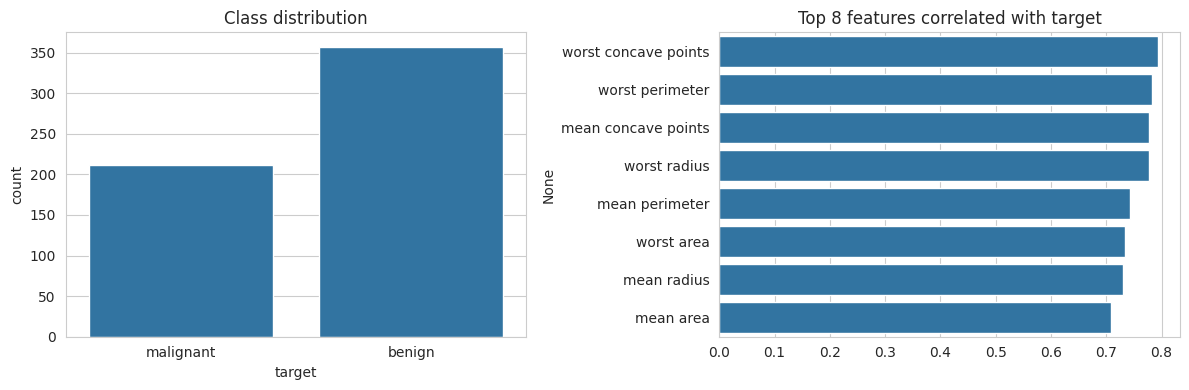

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=df['target'].map({0:'malignant',1:'benign'}), ax=ax[0])
ax[0].set_title("Class distribution")
top = df.corr()['target'].drop('target').abs().sort_values(ascending=False).head(8)
sns.barplot(x=top.values, y=top.index, ax=ax[1]); ax[1].set_title("Top 8 features correlated with target")
plt.tight_layout(); plt.show()

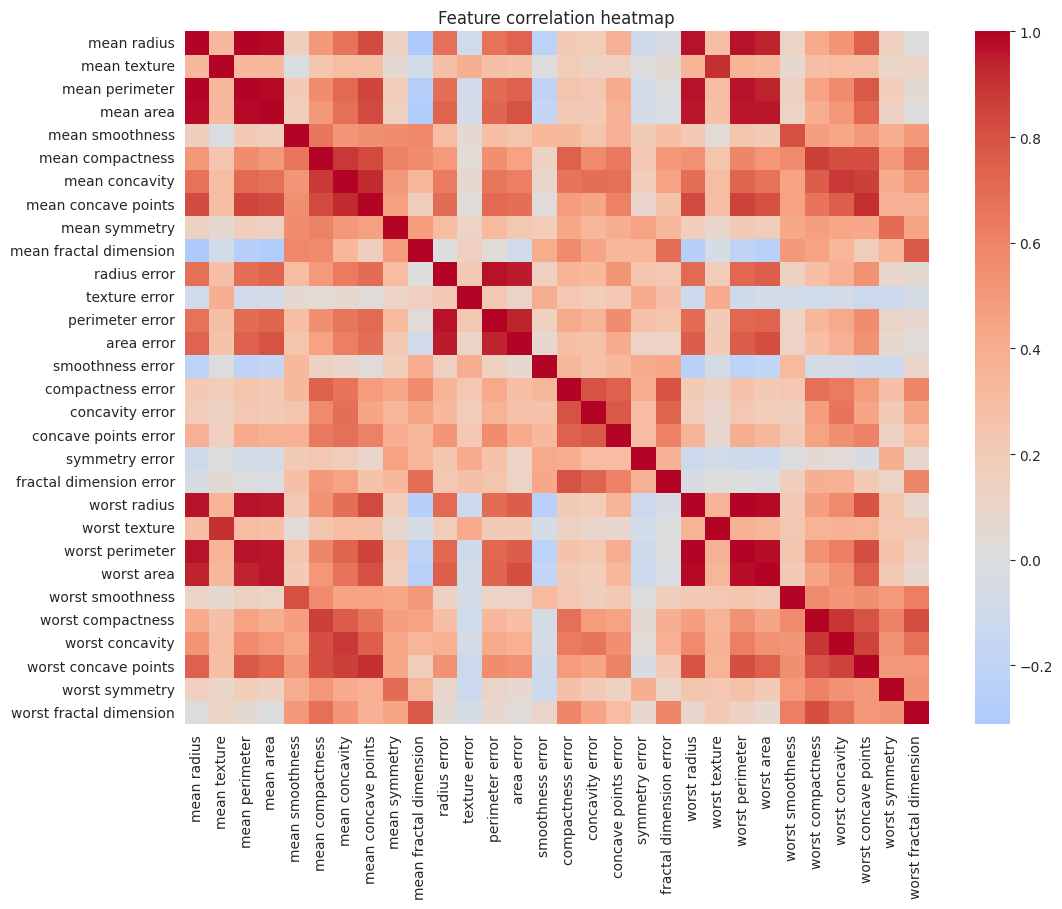

In [4]:
plt.figure(figsize=(12, 9))
sns.heatmap(df.drop(columns='target').corr(), cmap="coolwarm", center=0)
plt.title("Feature correlation heatmap"); plt.show()

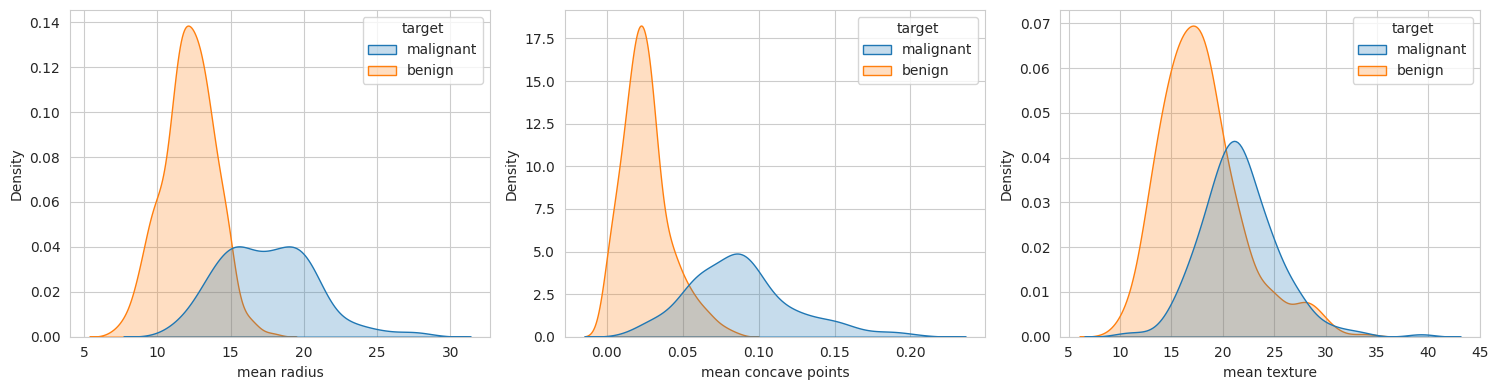

In [5]:
feats = ['mean radius', 'mean concave points', 'mean texture']
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, f in zip(ax, feats):
    sns.kdeplot(data=df, x=f, hue=df['target'].map({0:'malignant',1:'benign'}), fill=True, ax=a)
plt.tight_layout(); plt.show()

## 4. Train/test split (stratified 80/20) and scaling
Scaling is put inside a `Pipeline` so the scaler is fit only on training data (no data leakage).

In [6]:
X, y = df.drop(columns='target'), df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RS, stratify=y)
print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


## 5. Train and compare 4 models (5-fold CV + test set)

In [7]:
models = {
    "Logistic Regression": Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(max_iter=2000))]),
    "SVM": Pipeline([("sc", StandardScaler()), ("m", SVC(probability=True, random_state=RS))]),
    "Random Forest": Pipeline([("sc", StandardScaler()), ("m", RandomForestClassifier(n_estimators=300, random_state=RS))]),
    "XGBoost": Pipeline([("sc", StandardScaler()), ("m", XGBClassifier(eval_metric="logloss", random_state=RS))]),
}
cv = StratifiedKFold(5, shuffle=True, random_state=RS)
rows = []
for name, pipe in models.items():
    cv_f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1").mean()
    pipe.fit(X_train, y_train)
    pred, prob = pipe.predict(X_test), pipe.predict_proba(X_test)[:, 1]
    rows.append({"Model": name, "CV F1": cv_f1,
                 "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, prob)})
results = pd.DataFrame(rows).sort_values("F1", ascending=False).reset_index(drop=True)
results.round(4)

,Model,CV F1,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.9825,0.9825,0.9861,0.9861,0.9861,0.9954
1,SVM,0.9756,0.9825,0.9861,0.9861,0.9861,0.9950
2,XGBoost,0.9738,0.9561,0.9467,0.9861,0.9660,0.9927
3,Random Forest,0.9718,0.9474,0.9583,0.9583,0.9583,0.9937


## 6. ROC curves

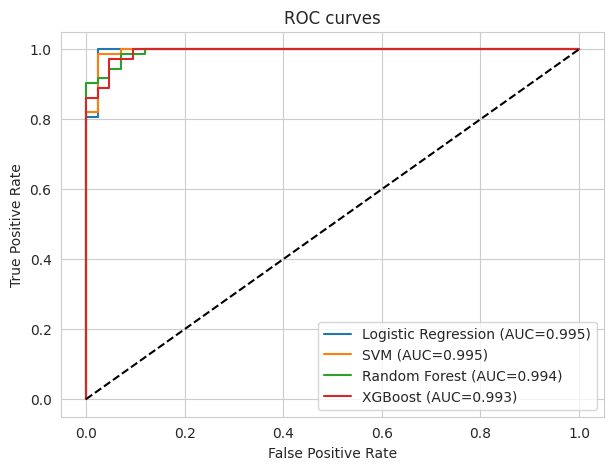

In [8]:
plt.figure(figsize=(7, 5))
for name, pipe in models.items():
    fpr, tpr, _ = roc_curve(y_test, pipe.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, pipe.predict_proba(X_test)[:,1]):.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC curves"); plt.legend(); plt.show()

## 7. Hyperparameter tuning (best model family: SVM + Logistic Regression grid)
We tune SVM with GridSearchCV, optimizing recall-aware F1.

In [9]:
grid = GridSearchCV(
    Pipeline([("sc", StandardScaler()), ("m", SVC(probability=True, random_state=RS))]),
    {"m__C": [0.1, 1, 10, 100], "m__gamma": ["scale", 0.01, 0.001], "m__kernel": ["rbf", "linear"]},
    cv=cv, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)
print("Best params:", grid.best_params_, "| CV F1:", round(grid.best_score_, 4))
tuned = grid.best_estimator_
pred, prob = tuned.predict(X_test), tuned.predict_proba(X_test)[:, 1]
print("Tuned SVM -> Acc %.4f | Prec %.4f | Rec %.4f | F1 %.4f | AUC %.4f" % (
    accuracy_score(y_test, pred), precision_score(y_test, pred), recall_score(y_test, pred),
    f1_score(y_test, pred), roc_auc_score(y_test, prob)))

Best params: {'m__C': 0.1, 'm__gamma': 'scale', 'm__kernel': 'linear'} | CV F1: 0.981
Tuned SVM -> Acc 0.9825 | Prec 0.9861 | Rec 0.9861 | F1 0.9861 | AUC 0.9937


## 8. Final model: confusion matrix and report

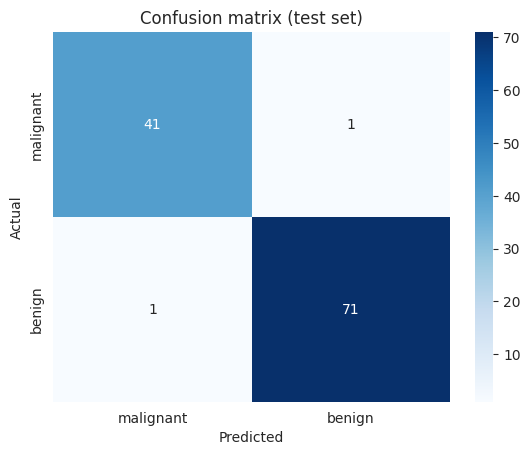

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [10]:
final = tuned
pred = final.predict(X_test)
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["malignant", "benign"], yticklabels=["malignant", "benign"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix (test set)"); plt.show()
print(classification_report(y_test, pred, target_names=["malignant", "benign"]))

## 9. Feature importance (Random Forest)

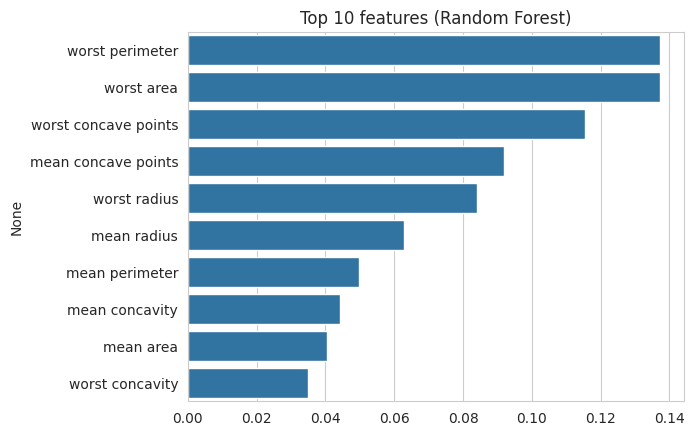

In [11]:
rf = models["Random Forest"].named_steps["m"]
imp = pd.Series(rf.feature_importances_, index=X.columns).nlargest(10)
sns.barplot(x=imp.values, y=imp.index); plt.title("Top 10 features (Random Forest)"); plt.show()

## 10. Save model and predict on a new patient

In [12]:
joblib.dump(final, "breast_cancer_model.joblib")
loaded = joblib.load("breast_cancer_model.joblib")
sample = X_test.iloc[[0]]
p = loaded.predict_proba(sample)[0]
print("Prediction:", "benign" if loaded.predict(sample)[0] == 1 else "malignant",
      "| P(malignant)=%.3f, P(benign)=%.3f" % (p[0], p[1]), "| Actual:", "benign" if y_test.iloc[0] == 1 else "malignant")

Prediction: malignant | P(malignant)=1.000, P(benign)=0.000 | Actual: malignant


## 11. Conclusion
- All four models score very high on this dataset; the tuned SVM / Logistic Regression are the most reliable.
- In medical screening **recall on the malignant class** matters most (a missed cancer is worse than a false alarm).
- Limitations: small dataset (569 rows), no external validation. This is an educational model, not a diagnostic tool.